<a href="https://colab.research.google.com/github/SamC1249/cs1090a-project/blob/main/Group_47_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 2: Data Wrangling — Dark Matter Halo Prediction Using Observable Galaxy Properties

**Canvas project group:** 47
**Members:** Benjamin Mujkic, Ian Kim, Sam Chen, Gavin Ni

**Goal of this notebook:** get the IllustrisTNG data, understand what it contains, clean it, and state a precise project question.

## 1. Getting the data

**Source:** [IllustrisTNG TNG100-1](https://www.tng-project.org/data/downloads/TNG100-1/), group catalog at snapshot 99 (redshift 0, i.e. "today").

**Size:** the full snapshot-99 group catalog is **4.1 GB** in 448 HDF5 files (6,291,349 halos, 4,371,211 subhalos). Our script `src/download_data.py` streams the 448 files through the TNG API one at a time, keeps only the columns we need, and deletes each file right away, so the full 4.1 GB is never stored. It:

1. keeps only the **central** galaxy of each halo (`GroupFirstSub`),
2. removes objects TNG flags as not real galaxies (`SubhaloFlag == 0`),
3. removes galaxies with stellar mass below $10^{8.5}\,M_\odot$ (fewer than ~350 star particles, too noisy),
4. converts masses from $10^{10} M_\odot/h$ to $M_\odot$ and sizes from ckpc/$h$ to kpc ($h = 0.6774$),
5. takes $\log_{10}$ of masses, sizes and specific SFR, and builds 4 colors from the magnitudes.

The result is committed to the repo, so rerunning the download is optional (it needs a free TNG API key in `.env`).

In [ ]:
import subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12})

DATA = Path("../data/tng100-1_snap99_centrals.csv")
REBUILD = False  # True: re-download from TNG (needs TNG_API_KEY in .env)
if REBUILD:
    subprocess.run([sys.executable, "../src/download_data.py"], check=True)

df = pd.read_csv(DATA)
print(f"file size: {DATA.stat().st_size / 1e6:.1f} MB")
print(f"shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

## 2. Understanding the data

**One row = one central galaxy** in the TNG100-1 simulation at redshift 0.

| Column | Meaning | Units |
|---|---|---|
| `subhalo_id` | galaxy ID in the TNG catalog | — |
| `log_mhalo` | **target**: halo mass $M_{200c}$ (mass inside the radius where mean density is 200× the critical density) | log $M_\odot$ |
| `log_r200` | halo radius $R_{200c}$ | log kpc |
| `log_mstar` | stellar mass within twice the stellar half-mass radius | log $M_\odot$ |
| `log_size_star` | stellar half-mass radius | log kpc |
| `sfr` | star formation rate | $M_\odot$/yr |
| `log_ssfr` | specific SFR = SFR / stellar mass | log yr$^{-1}$ |
| `gas_metallicity`, `star_metallicity` | mass fraction of heavy elements in gas / stars | — |
| `vmax` | peak circular velocity of the subhalo (all particles) | km/s |
| `veldisp` | velocity dispersion of all particles in the subhalo | km/s |
| `mag_U` … `mag_z` | absolute magnitudes in 8 bands (U, B, V, K, g, r, i, z); more negative = brighter | mag |
| `color_gr`, `color_ri`, `color_UV`, `color_VK` | differences of two magnitudes; larger = redder | mag |

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17464 entries, 0 to 17463
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   subhalo_id        17464 non-null  int64  
 1   log_mhalo         17464 non-null  float64
 2   log_r200          17464 non-null  float64
 3   log_mstar         17464 non-null  float64
 4   log_size_star     17464 non-null  float64
 5   sfr               17464 non-null  float64
 6   log_ssfr          17464 non-null  float64
 7   gas_metallicity   17464 non-null  float64
 8   star_metallicity  17464 non-null  float64
 9   vmax              17464 non-null  float64
 10  veldisp           17464 non-null  float64
 11  mag_U             17464 non-null  float64
 12  mag_B             17464 non-null  float64
 13  mag_V             17464 non-null  float64
 14  mag_K             17464 non-null  float64
 15  mag_g             17464 non-null  float64
 16  mag_r             17464 non-null  float64
 17  mag_

In [ ]:
df.describe().T[['mean', 'std', 'min', 'max']].round(3)

,mean,std,min,max
subhalo_id,606440.659,86501.957,0.000,1057646.000
log_mhalo,11.382,0.491,8.843,14.581
log_r200,2.118,0.164,1.272,3.184
log_mstar,9.375,0.676,8.500,12.384
log_size_star,0.507,0.215,-0.435,2.115
sfr,0.440,1.187,0.000,98.667
log_ssfr,-10.442,1.536,-17.168,-8.615
gas_metallicity,0.012,0.006,0.000,0.058
star_metallicity,0.013,0.006,0.003,0.034
vmax,123.621,61.620,40.809,999.385


**The target.** Halo mass spans almost 6 orders of magnitude, so we model it in log units. Most halos are $10^{11}$–$10^{12} M_\odot$; massive halos are rare.

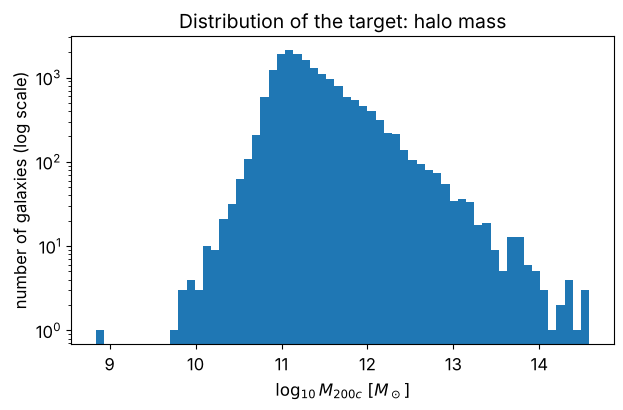

count    17464.00
mean        11.38
std          0.49
min          8.84
25%         11.05
50%         11.26
75%         11.61
max         14.58
Name: log_mhalo, dtype: float64
galaxies with halo mass above 1e13: 182


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["log_mhalo"], bins=60, color="tab:blue")
ax.set_yscale("log")
ax.set_xlabel(r"$\log_{10} M_{200c}\ [M_\odot]$")
ax.set_ylabel("number of galaxies (log scale)")
ax.set_title("Distribution of the target: halo mass")
plt.show()
print(df["log_mhalo"].describe().round(2))
print("galaxies with halo mass above 1e13:", (df["log_mhalo"] > 13).sum())

**The known baseline relation.** Stellar mass tracks halo mass closely, but with scatter. Explaining that scatter with other observables is the point of the project.

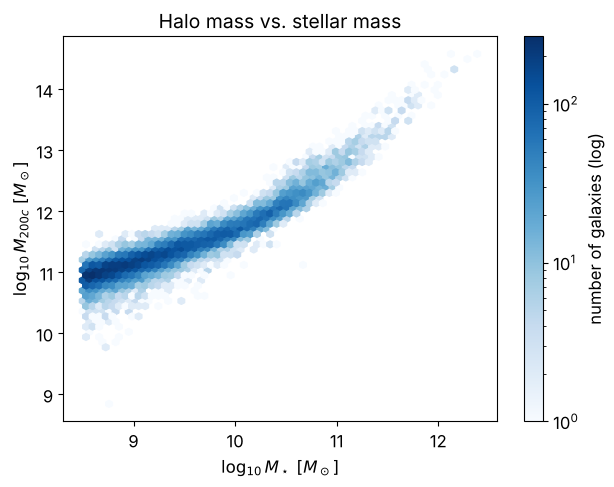

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
hb = ax.hexbin(df["log_mstar"], df["log_mhalo"], gridsize=60, bins="log", cmap="Blues", mincnt=1)
fig.colorbar(hb, label="number of galaxies (log)")
ax.set_xlabel(r"$\log_{10} M_\star\ [M_\odot]$")
ax.set_ylabel(r"$\log_{10} M_{200c}\ [M_\odot]$")
ax.set_title("Halo mass vs. stellar mass")
plt.show()

## 3. Cleaning and preprocessing

### 3.1 Duplicates and missing values

In [ ]:
print("duplicate rows:", df.duplicated().sum())
print("duplicate galaxy IDs:", df["subhalo_id"].duplicated().sum())
print("missing values:", df.isna().sum().sum())
print("infinite values:", np.isinf(df.select_dtypes("number")).sum().sum())

duplicate rows: 0
duplicate galaxy IDs: 0
missing values: 0
infinite values: 0


No duplicates, no missing values, no infinities. But a parsed number is not necessarily a *measured* number, so we look for hidden missing values next.

### 3.2 Hidden missing values: zeros

In [ ]:
sfr_zero = df["sfr"] == 0
no_gas = df["gas_metallicity"] == 0
print(f"SFR = 0:              {sfr_zero.sum():,} galaxies ({sfr_zero.mean():.1%})")
print(f"gas metallicity = 0:  {no_gas.sum():,} galaxies ({no_gas.mean():.1%})")
print(f"both:                 {(sfr_zero & no_gas).sum():,}")

SFR = 0:              1,477 galaxies (8.5%)
gas metallicity = 0:  377 galaxies (2.2%)
both:                 377


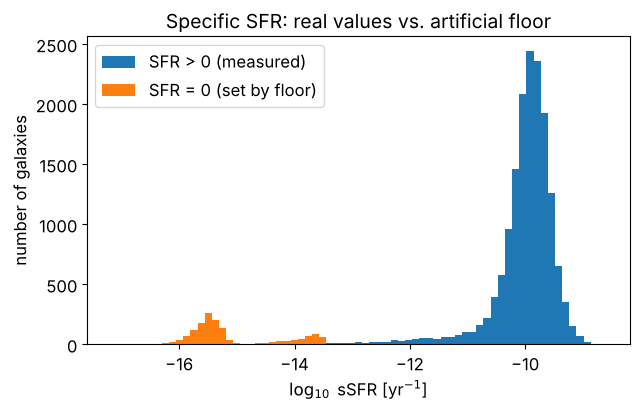

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(df["log_ssfr"].min(), df["log_ssfr"].max(), 70)
ax.hist(df.loc[~sfr_zero, "log_ssfr"], bins=bins, label="SFR > 0 (measured)", color="tab:blue")
ax.hist(df.loc[sfr_zero, "log_ssfr"], bins=bins, label="SFR = 0 (set by floor)", color="tab:orange")
ax.set_xlabel(r"$\log_{10}$ sSFR [yr$^{-1}$]")
ax.set_ylabel("number of galaxies")
ax.set_title("Specific SFR: real values vs. artificial floor")
ax.legend()
plt.show()

`log(0)` is undefined, so the download script replaced SFR = 0 with $10^{-5}$. The orange values are therefore **not measurements**. Every galaxy with no gas also has SFR = 0.

These zeros are **not random**: they belong to galaxies that stopped forming stars (mostly red, old galaxies). Dropping them would bias the sample toward star-forming galaxies, and filling them with a single constant distorts the distribution (Section 6). **Decision:** keep the rows and add two yes/no flags, `sfr_zero` and `no_gas`, so models can treat these galaxies separately.

In [ ]:
df["sfr_zero"] = sfr_zero.astype(int)
df["no_gas"] = no_gas.astype(int)

### 3.3 Unusual values

In [ ]:
odd = df["log_mhalo"] - df["log_mstar"] < 1
df.loc[odd, ["subhalo_id", "log_mhalo", "log_mstar", "sfr", "gas_metallicity"]]

,subhalo_id,log_mhalo,log_mstar,sfr,gas_metallicity
5399,585369,11.117651,10.644780,0.0,0.0354
16981,719337,10.585988,9.719537,0.0,0.0000
17105,727485,10.602178,9.634319,0.0,0.0000
17463,1057646,8.842744,8.756192,0.0,0.0000


In every other galaxy the halo is at least 10× heavier than the stars. These 4 galaxies have halos barely heavier than their stars, and none of them form stars; 3 have no gas. This suggests they lost most of their dark matter in a past interaction, which makes them unlike the typical central galaxies our question is about. **Decision:** remove them (4 of 17,464, 0.02%).

In [ ]:
df = df.loc[~odd].reset_index(drop=True)
print(f"rows after removing unusual galaxies: {len(df):,}")

rows after removing unusual galaxies: 17,460


### 3.4 Information leakage

A feature must be something a telescope could observe. Three columns fail this test:

- **`log_r200`** is computed directly from halo mass ($M_{200c} \propto R_{200c}^3$), so it encodes the target exactly.
- **`vmax`** and **`veldisp`** are computed by TNG from *all* particles in the subhalo, which are mostly dark matter. They partly measure the halo itself and cannot be observed. In a first test model, `veldisp` alone carried 98% of the feature importance, the typical sign of leakage.

**Decision:** keep them in the table for reference, but never use them as features.

In [ ]:
LEAKY = ["log_r200", "vmax", "veldisp"]
print(df[["log_mhalo"] + LEAKY].corr()["log_mhalo"].round(3))

log_mhalo    1.000
log_r200     1.000
vmax         0.934
veldisp      0.929
Name: log_mhalo, dtype: float64


### 3.5 Collinearity among the magnitudes

The 8 magnitudes are mostly a second measurement of stellar mass (brighter = more stars).

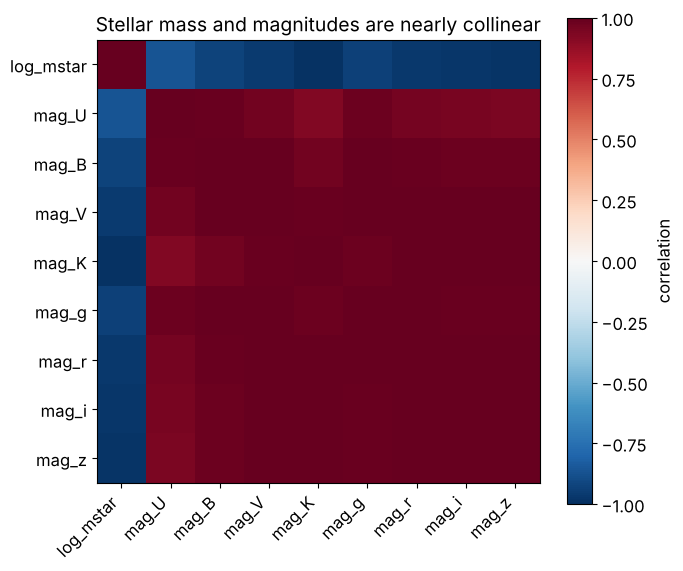

In [ ]:
mags = ["mag_U", "mag_B", "mag_V", "mag_K", "mag_g", "mag_r", "mag_i", "mag_z"]
corr = df[["log_mstar"] + mags].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(im, label="correlation")
ax.set_title("Stellar mass and magnitudes are nearly collinear")
plt.tight_layout()
plt.show()

Correlations with stellar mass range from 0.86 (U band) to 0.99 (K band) in absolute value, and neighboring bands correlate at up to 1.00. Using all 8 magnitudes together with stellar mass would make regression coefficients unstable. **Decision:** use stellar mass plus the 4 colors, which carry the information the magnitudes add beyond mass (how red or blue the galaxy is), and leave the raw magnitudes out.

### 3.6 Final features and their scales

In [ ]:
TARGET = "log_mhalo"
FEATURES = ["log_mstar", "color_gr", "color_ri", "color_UV", "color_VK",
            "log_size_star", "log_ssfr", "gas_metallicity", "star_metallicity",
            "sfr_zero", "no_gas"]
df[FEATURES].describe().T[["min", "max", "std"]].round(3)

,min,max,std
log_mstar,8.500,12.384,0.676
color_gr,-0.037,0.812,0.157
color_ri,-0.001,0.391,0.065
color_UV,-0.540,1.449,0.370
color_VK,1.381,3.120,0.274
log_size_star,-0.435,2.115,0.215
log_ssfr,-17.168,-8.615,1.535
gas_metallicity,0.000,0.058,0.006
star_metallicity,0.003,0.034,0.006
sfr_zero,0.000,1.000,0.278


The features span very different ranges (metallicities ~0.01, magnitudes of mass ~10, sSFR ~−10), so they will be standardized inside a pipeline before regularized or distance-based models.

Class imbalance does not apply: this is a regression problem. The analogous issue is the rare high-mass halos (only 182 above $10^{13} M_\odot$), which we will check separately.

In [ ]:
OUT = Path("../data/tng100-1_snap99_centrals_clean.csv")
df.to_csv(OUT, index=False)
print(f"cleaned table: {df.shape[0]:,} rows x {df.shape[1]} columns -> {OUT}")

cleaned table: 17,460 rows x 25 columns -> ../data/tng100-1_snap99_centrals_clean.csv


## 4. Revised project question

**Using only properties a telescope could observe (stellar mass, colors, size, specific star formation rate, and metallicity), can we predict the dark matter halo mass ($\log M_{200c}$) of central galaxies in TNG100-1 with a lower test RMSE than a linear regression on stellar mass alone, and which of these properties add the most?**

At the end of the project we will know whether it was answered: compare the test RMSE (in dex) of our best observable-only model with the stellar-mass baseline, and report which features drive the improvement.